<a href="https://colab.research.google.com/github/Mathieuuu122/DiabetesClassification-withArtificialNeurons/blob/main/Diabetes_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
from google.colab import files
uploaded = files.upload()

Saving diabetes.xls to diabetes (1).xls


## Data audit and visualizations (Azemo)
Overview of the dataset: size, types, summary statistics, label balance
and the main relationships between features.

In [20]:
df.info()
print(df.describe())
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.

The dataset has 768 records, 8 features and 1 label (Outcome).
There are 500 negative cases (about 65%) and 268 positive cases (about 35%),
so the classes are imbalanced. In describe(), several columns (Glucose,
BloodPressure, SkinThickness, Insulin, BMI) have a minimum of 0, which is
biologically impossible and probably encodes missing values.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Outcome", data=df)
plt.title("Label distribution (0 = negative, 1 = positive)")
plt.show()

The label distribution is imbalanced: about 65% of the patients are negative.
A model that always predicts 0 would already reach about 65% accuracy.

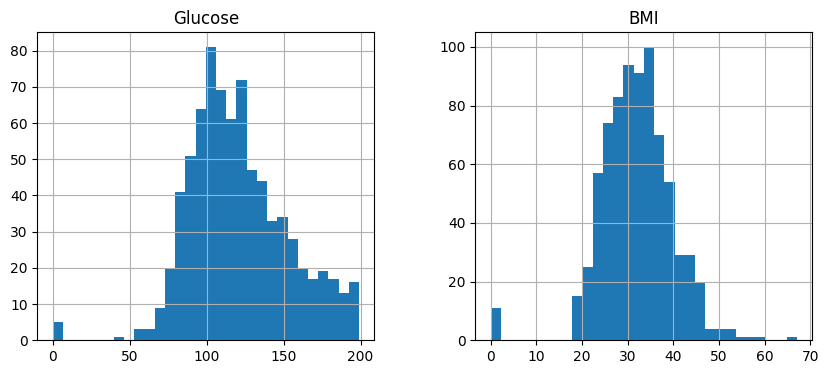

In [21]:
df[["Glucose", "BMI"]].hist(bins=30, figsize=(10, 4))
plt.show()


Glucose and BMI are roughly bell-shaped, but both contain values at 0,
which are implausible measurements. These will be treated as missing values.

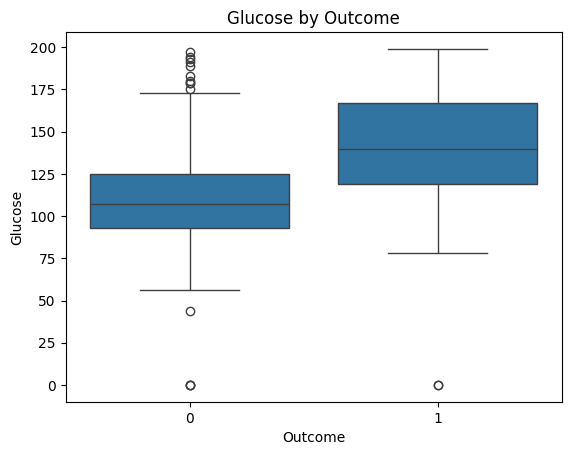

In [22]:
sns.boxplot(x="Outcome", y="Glucose", data=df)
plt.title("Glucose by Outcome")
plt.show()

Patients with Outcome = 1 tend to have higher glucose than patients with
Outcome = 0, so Glucose looks like an informative feature.

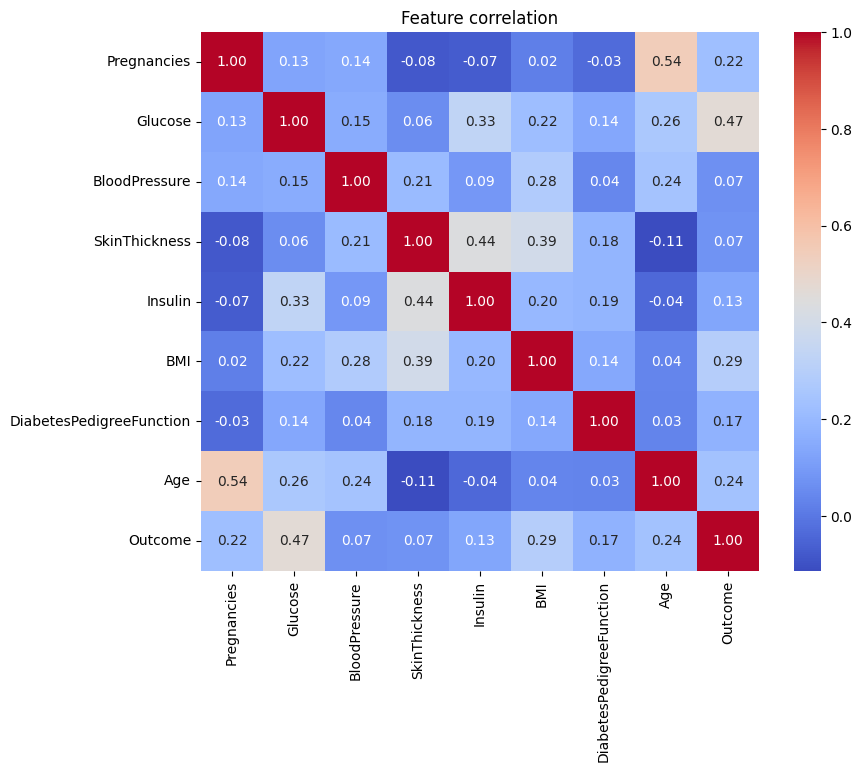

In [23]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation")
plt.show()

Glucose has the strongest correlation with Outcome. The features are only
moderately correlated with each other, so there is little redundancy.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on train
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print(X_train_s.shape, X_val_s.shape, X_test_s.shape)
print("Train mean:", X_train_s.mean(axis=0).round(2))
print("Train std :", X_train_s.std(axis=0).round(2))

(460, 8) (154, 8) (154, 8)
Train mean: [-0. -0. -0.  0. -0. -0.  0.  0.]
Train std : [1. 1. 1. 1. 1. 1. 1. 1.]


In [25]:
import numpy as np
from sklearn.model_selection import train_test_split

# TEMPORARY - to be replaced by Mathieu's split + imputation
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# zeros -> NaN -> median computed on TRAIN only
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()
for d in (X_train, X_val, X_test):
    d[cols] = d[cols].replace(0, np.nan)
medians = X_train[cols].median()
for d in (X_train, X_val, X_test):
    d[cols] = d[cols].fillna(medians)

print(X_train.shape, X_val.shape, X_test.shape)

(460, 8) (154, 8) (154, 8)


## M0: majority-class baseline (Azemo)
M0 always predicts the most frequent class of the training set (0).
It is the minimal reference that M1 and M2 must beat.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

m0 = DummyClassifier(strategy="most_frequent")
m0.fit(X_train_s, y_train)
pred_m0_val = m0.predict(X_val_s)

print("Accuracy :", accuracy_score(y_val, pred_m0_val))
print("Precision:", precision_score(y_val, pred_m0_val, zero_division=0))
print("Recall   :", recall_score(y_val, pred_m0_val, zero_division=0))
print("F1       :", f1_score(y_val, pred_m0_val, zero_division=0))

cm = confusion_matrix(y_val, pred_m0_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("M0 confusion matrix (validation)")
plt.show()

In [ ]:
##phase 3
import torch
import torch.nn as nn

def to_tensors(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y.values, dtype=torch.float32).reshape(-1, 1))

X_train_t, y_train_t = to_tensors(X_train_s, y_train)
X_val_t,   y_val_t   = to_tensors(X_val_s, y_val)
X_test_t,  y_test_t  = to_tensors(X_test_s, y_test)

## M2: multilayer perceptron (Azemo)
Architecture: 8 inputs -> 8 hidden neurons (ReLU) -> 1 output logit.
The hidden layer with a non-linear activation lets the network learn
non-linear relationships that a single neuron cannot capture.
The sigmoid is NOT in the model: BCEWithLogitsLoss applies it internally
in a numerically stable way, and we use torch.sigmoid only at evaluation time.

In [ ]:
torch.manual_seed(42)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(8, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )
    def forward(self, x):
        return self.net(x)

m2 = MLP()
print(m2)
print("Output shape:", m2(X_train_t[:5]).shape)   # expect [5, 1]

### Training loop
Each epoch has five steps:
1. zero_grad(): reset the gradients from the previous step
2. forward pass: compute the logits from the inputs
3. loss: compare the logits with the true labels (BCEWithLogitsLoss)
4. backward(): backpropagation, PyTorch computes the gradient of the loss
   with respect to every weight
5. step(): the Adam optimizer updates the weights using these gradients
After each epoch we also compute the validation loss, without updating
the weights.

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(m2.parameters(), lr=0.01)

train_losses, val_losses = [], []

for epoch in range(200):
    m2.train()
    optimizer.zero_grad()
    logits = m2(X_train_t)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

    m2.eval()
    with torch.no_grad():
        val_loss = criterion(m2(X_val_t), y_val_t)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}: train loss {loss.item():.4f} | val loss {val_loss.item():.4f}")

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("BCE loss")
plt.title("M2 learning curves")
plt.legend(); plt.show()

In [ ]:
import os
print(os.listdir('.'))

In [ ]:
import pandas as pd

# Since the Pima dataset is natively a CSV file, use read_csv:
df = pd.read_csv('diabetes.xls')

# Check shape and view the first few rows
print("Dataset Shape:", df.shape)
df.head()